# Proyecto final 


## Descripción de la actividad: Mini proyecto de análisis de datos utilizando un conjunto de datos propio.

### El proyecto debe incluir:
#### - Carga de datos.
#### - Exploración básica.
#### - Al menos una visualización.
#### - Una función propia.
#### - Conclusiones breves.

## El presente proyecto es la conclusión de las actividades previas a la Ocean Hack Week en español. De modo que, se utilizará la misma base de datos que en los dos ejercicios anteriores, la cual contiene estimaciones satelitales de biomasa húmeda de sargazo flotante del Caribe mexicano correspondientes al año 2025.

In [1]:
# Carga de librerías que se utilizarán en el script

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [2]:
# Importación de la base de datos

sargazo = pd.read_csv("SATsum_diaria_2dr_2025_zee_caribbean_2026-11-09_1332.csv")


In [3]:
# Exploración de la base de datos: 

#Número de filas y columnas
sargazo.shape

(365, 8)

In [4]:
# Exploración de la base de datos: 

#Nombre de las variables
sargazo.columns

Index(['Date', 'Year', 'Month', 'Day', 'Day product · MODIS Aqua+Terra (t)',
       '2-day combined product · 2dr · OFFICIAL daily figure (t)',
       'Area of the 2-day combined (km2)', 'Zone'],
      dtype='str')

In [5]:

#Visualización de las primeras 10 filas
sargazo.head(10)

,Date,Year,Month,Day,Day product · MODIS Aqua+Terra (t),2-day combined product · 2dr · OFFICIAL daily figure (t),Area of the 2-day combined (km2),Zone
0,2025-01-01,2025,1,1,88,88,9,Mexican Caribbean EEZ
1,2025-01-02,2025,1,2,0,88,9,Mexican Caribbean EEZ
2,2025-01-03,2025,1,3,627,627,42,Mexican Caribbean EEZ
3,2025-01-04,2025,1,4,0,627,42,Mexican Caribbean EEZ
4,2025-01-05,2025,1,5,0,0,0,Mexican Caribbean EEZ
5,2025-01-06,2025,1,6,64,64,10,Mexican Caribbean EEZ
6,2025-01-07,2025,1,7,0,64,10,Mexican Caribbean EEZ
7,2025-01-08,2025,1,8,0,0,0,Mexican Caribbean EEZ
8,2025-01-09,2025,1,9,0,0,0,Mexican Caribbean EEZ
9,2025-01-10,2025,1,10,0,0,0,Mexican Caribbean EEZ


In [6]:
# Exploración de la base de datos: 

#Información general de la base de datos
sargazo.info()

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 8 columns):
 #   Column                                                    Non-Null Count  Dtype
---  ------                                                    --------------  -----
 0   Date                                                      365 non-null    str  
 1   Year                                                      365 non-null    int64
 2   Month                                                     365 non-null    int64
 3   Day                                                       365 non-null    int64
 4   Day product · MODIS Aqua+Terra (t)                        365 non-null    int64
 5   2-day combined product · 2dr · OFFICIAL daily figure (t)  365 non-null    int64
 6   Area of the 2-day combined (km2)                          365 non-null    int64
 7   Zone                                                      365 non-null    str  
dtypes: int64(6), str(2)
memory usage: 34.0 KB


In [7]:
# Exploración visual de la base de datos (para fines de la actividad el enfoque será únicamente en la variable de producto diario en toneladas).

#Serie temporal del producto diario de sargazo

#Correción de formato adecuado para la fecha

sargazo["Date"] = pd.to_datetime(sargazo["Date"])

sargazo = sargazo.sort_values("Date")

sargazo.info()




<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 8 columns):
 #   Column                                                    Non-Null Count  Dtype         
---  ------                                                    --------------  -----         
 0   Date                                                      365 non-null    datetime64[us]
 1   Year                                                      365 non-null    int64         
 2   Month                                                     365 non-null    int64         
 3   Day                                                       365 non-null    int64         
 4   Day product · MODIS Aqua+Terra (t)                        365 non-null    int64         
 5   2-day combined product · 2dr · OFFICIAL daily figure (t)  365 non-null    int64         
 6   Area of the 2-day combined (km2)                          365 non-null    int64         
 7   Zone                                                    

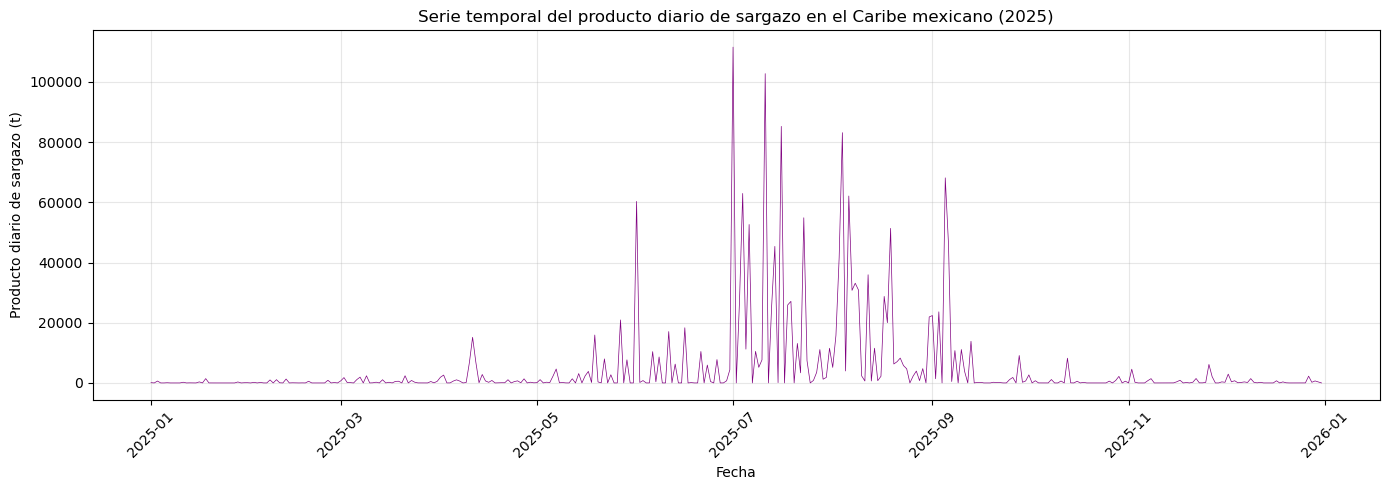

In [8]:
# Exploración visual de la base de datos (para fines de la actividad el enfoque será únicamente en la variable de producto diario en toneladas).

#Serie temporal del producto diario de sargazo

plt.figure(figsize=(14,5))

plt.plot(
    sargazo["Date"],
    sargazo["Day product · MODIS Aqua+Terra (t)"],
    color="purple",
    linewidth=0.5
)

plt.xlabel("Fecha")
plt.ylabel("Producto diario de sargazo (t)")
plt.title("Serie temporal del producto diario de sargazo en el Caribe mexicano (2025)")

plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [9]:
# Se retoma la función generada en la tarea 2. 

# Aplicabilidad: identificación de días con mayor abundancia de sargazo (que sobrepasen el percentil 90)

def identificar_p90(datos, variable):
    percentil_90 = datos[variable].quantile(0.90)

#Filtrado de las filas para conservar únicamente aquellas en las que la variable supera el umbral establecido. 
    
    dias_max = datos[datos[variable]> percentil_90]

    return dias_max[["Date", variable]]


In [10]:
# Ejecución de la función

dias_p90 = identificar_p90(
    sargazo, 
    "Day product · MODIS Aqua+Terra (t)"
)

print(dias_p90)

          Date  Day product · MODIS Aqua+Terra (t)
100 2025-04-11                               15170
138 2025-05-19                               15919
146 2025-05-27                               20937
151 2025-06-01                               60329
161 2025-06-11                               17068
166 2025-06-16                               18332
181 2025-07-01                              111587
183 2025-07-03                               26984
184 2025-07-04                               62963
186 2025-07-06                               52643
191 2025-07-11                              102776
193 2025-07-13                               25476
194 2025-07-14                               45376
196 2025-07-16                               85254
198 2025-07-18                               25911
199 2025-07-19                               27115
201 2025-07-21                               13133
203 2025-07-23                               54879
211 2025-07-31                 

In [11]:
# Es de interés conocer los patrones intranuales, de modo que se cuantifican los días con abundancia sobre el percentil 90 por mes. 

# Contabilizar días superiores al P90 por mes

dias_por_mes = (
    pd.to_datetime(dias_p90["Date"])
    .dt.month
    .value_counts()
    .reindex(range(1,13), fill_value=0)
    .sort_index()
)

# Asignar nombres a los meses

dias_por_mes.index = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

print(dias_por_mes)

Enero          0
Febrero        0
Marzo          0
Abril          1
Mayo           2
Junio          3
Julio         13
Agosto        13
Septiembre     5
Octubre        0
Noviembre      0
Diciembre      0
Name: count, dtype: int64


In [12]:
# Cuantificación de días que sobrepasan el percentil 90

print ("Número de días superiores al P90:", len(dias_p90))

Número de días superiores al P90: 37


In [13]:
# Cálculo del percentil 90

variable = "Day product · MODIS Aqua+Terra (t)"

p90 = sargazo[variable].quantile(0.90)

print("Valor del percentil 90:", p90, "toneladas")

Valor del percentil 90: 11413.400000000007 toneladas


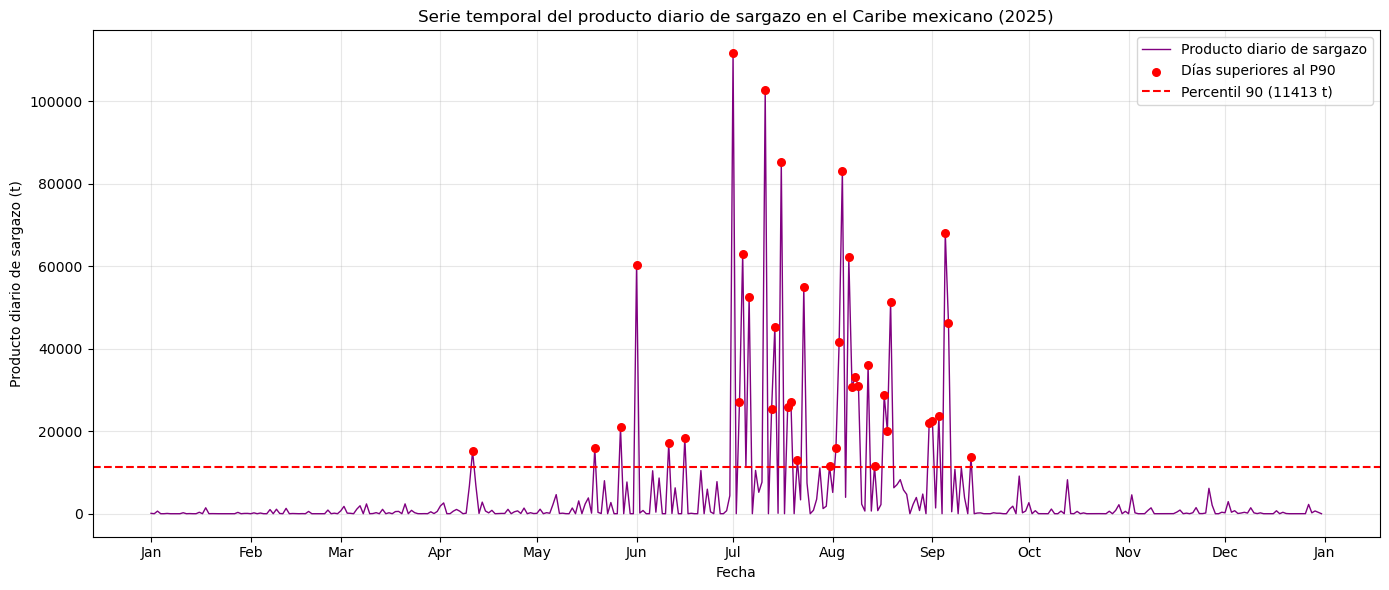

In [14]:
#Se actulaliza la primera gráfica con esta información

# Serie temporal del producto diario de sargazo y línea P90

plt.figure(figsize=(14,6))


plt.plot(
    sargazo["Date"],
    sargazo[variable],
    color="purple",
    linewidth=1,
    label="Producto diario de sargazo"
)

# Identificación de días superiores al P90
plt.scatter(
    dias_p90["Date"],
    dias_p90[variable],
    color="red",
    s=30,
    label="Días superiores al P90",
    zorder=3
)

# Línea horizontal del percentil 90
plt.axhline(
    y=p90,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Percentil 90 ({p90:.0f} t)"
)

# Etiquetas y título
plt.xlabel("Fecha")
plt.ylabel("Producto diario de sargazo (t)")
plt.title("Serie temporal del producto diario de sargazo en el Caribe mexicano (2025)")

# Formato del eje X
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Conclusión: 
#### El análisis de la variabilidad temporal del producto diario de sargazo durante 2025 permitió identificar patrones de distribución intranual, así como periodos con valores particularmente elevados. La representación de la serie temporal mostró una mayor concentración de valores elevados entre junio y septiembre. A partir del cálculo del percentil 90 (P90), cuyo umbral fue de 11,413 toneladas, se identificaron 37 días con valores superiores a este umbral. Estos registros representan aproximadamente el 10 % de las observaciones anuales y permiten reconocer los periodos con mayor abundancia relativa del producto diario de sargazo. Sin embargo, debe considerarse que son estimaciones generadas a partir de productos satelitales y no implica que en su totalidad vaya a recalar en las costas. Siguiendo esa misma idea, los días que superan el percentil 90 no representan eventos de arribazón masiva.

##### Referencia bibliográfica
##### Cerdeira-Estrada, S., R. Martell-Dubois, L. Rosique-de la Cruz, H. Caballero-Aragón, E. Santamaría-del-Ángel, V. Hernández-Díaz y R. Jiménez Rosenberg. 2026. Satellite-based Early Warning System for Sargassum (SATsum) in the Marine-Coastal Information and Analysis System (SIMAR+). Comisión Nacional para el Conocimiento y Uso de la Biodiversidad (CONABIO). Disponible en: https://simar.conabio.gob.mx/satsum